In [1]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

Mounted at /content/drive


In [2]:
file_path = '/content/drive/MyDrive/laptops.csv'

df = pd.read_csv(file_path, encoding='latin1')

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

display(df.head())

Dataset Shape: (1303, 13)

Column Names:
['Manufacturer', 'Model Name', 'Category', 'Screen Size', 'Screen', 'CPU', 'RAM', 'Storage', 'GPU', 'Operating System', 'Operating System Version', 'Weight', 'Price (Euros)']


,Manufacturer,Model Name,Category,Screen Size,Screen,CPU,RAM,Storage,GPU,Operating System,Operating System Version,Weight,Price (Euros)
0,Apple,MacBook Pro,Ultrabook,"13.3""",IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,NaN,1.37kg,"1339,69"
1,Apple,Macbook Air,Ultrabook,"13.3""",1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,NaN,1.34kg,"898,94"
2,HP,250 G6,Notebook,"15.6""",Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,NaN,1.86kg,"575,00"
3,Apple,MacBook Pro,Ultrabook,"15.4""",IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,NaN,1.83kg,"2537,45"
4,Apple,MacBook Pro,Ultrabook,"13.3""",IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,NaN,1.37kg,"1803,60"


In [3]:
# Convert numerical columns
df["Screen Size"] = pd.to_numeric(
    df["Screen Size"].astype(str).str.replace('"', '', regex=False),
    errors="coerce"
)

df["RAM"] = pd.to_numeric(
    df["RAM"].astype(str).str.replace("GB", "", regex=False),
    errors="coerce"
)

df["Weight"] = pd.to_numeric(
    df["Weight"].astype(str).str.replace("kg", "", regex=False),
    errors="coerce"
)

df["Price (Euros)"] = pd.to_numeric(
    df["Price (Euros)"].astype(str).str.replace(",", ".", regex=False),
    errors="coerce"
)

# Remove rows without a manufacturer label
df = df.dropna(subset=["Manufacturer"])

print("Cleaned Dataset Shape:", df.shape)
display(df.head())

Cleaned Dataset Shape: (1303, 13)


,Manufacturer,Model Name,Category,Screen Size,Screen,CPU,RAM,Storage,GPU,Operating System,Operating System Version,Weight,Price (Euros)
0,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8,128GB SSD,Intel Iris Plus Graphics 640,macOS,NaN,1.37,1339.69
1,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8,128GB Flash Storage,Intel HD Graphics 6000,macOS,NaN,1.34,898.94
2,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8,256GB SSD,Intel HD Graphics 620,No OS,NaN,1.86,575.00
3,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16,512GB SSD,AMD Radeon Pro 455,macOS,NaN,1.83,2537.45
4,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8,256GB SSD,Intel Iris Plus Graphics 650,macOS,NaN,1.37,1803.60


In [4]:
X = df.drop(columns=["Manufacturer", "Model Name"])
y = df["Manufacturer"].astype(str)

# Identify numerical and categorical features
numerical_features = [
    "Screen Size",
    "RAM",
    "Weight",
    "Price (Euros)"
]

categorical_features = [
    col for col in X.columns
    if col not in numerical_features
]

print("Input Features:")
print(X.columns.tolist())

print("\nTarget Classes:")
print(sorted(y.unique()))

print("\nNumber of Manufacturers:", y.nunique())

Input Features:
['Category', 'Screen Size', 'Screen', 'CPU', 'RAM', 'Storage', 'GPU', 'Operating System', 'Operating System Version', 'Weight', 'Price (Euros)']

Target Classes:
['Acer', 'Apple', 'Asus', 'Chuwi', 'Dell', 'Fujitsu', 'Google', 'HP', 'Huawei', 'LG', 'Lenovo', 'MSI', 'Mediacom', 'Microsoft', 'Razer', 'Samsung', 'Toshiba', 'Vero', 'Xiaomi']

Number of Manufacturers: 19


In [5]:
le = LabelEncoder()
y_encoded = le.fit_transform(y)

x_train, x_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.30,
    random_state=123,
    stratify=y_encoded
)

print("Training Features:", x_train.shape)
print("Testing Features:", x_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (912, 11)
Testing Features: (391, 11)
Training Target: (912,)
Testing Target: (391,)


In [6]:
numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessor = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Unknown"
    )),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_preprocessor, numerical_features),
    ("categorical", categorical_preprocessor, categorical_features)
])

In [7]:
id3_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", DecisionTreeClassifier(
        criterion="entropy",
        random_state=1234
    ))
])

id3_model.fit(x_train, y_train)

print("ID3 Decision Tree Trained Successfully!")

ID3 Decision Tree Trained Successfully!


In [8]:
y_pred_id3 = id3_model.predict(x_test)

print("ID3 Accuracy:",
      round(accuracy_score(y_test, y_pred_id3) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_id3,
    labels=np.arange(len(le.classes_)),
    target_names=le.classes_,
    zero_division=0
))

ID3 Accuracy: 57.03 %

Classification Report:
              precision    recall  f1-score   support

        Acer       0.54      0.48      0.51        31
       Apple       1.00      0.83      0.91         6
        Asus       0.51      0.54      0.53        48
       Chuwi       0.00      0.00      0.00         1
        Dell       0.67      0.63      0.65        89
     Fujitsu       0.00      0.00      0.00         1
      Google       1.00      1.00      1.00         1
          HP       0.58      0.57      0.58        82
      Huawei       0.00      0.00      0.00         1
          LG       1.00      1.00      1.00         1
      Lenovo       0.55      0.60      0.57        89
         MSI       0.53      0.62      0.57        16
    Mediacom       0.67      1.00      0.80         2
   Microsoft       0.00      0.00      0.00         2
       Razer       0.50      0.50      0.50         2
     Samsung       0.00      0.00      0.00         3
     Toshiba       0.25      0.29  

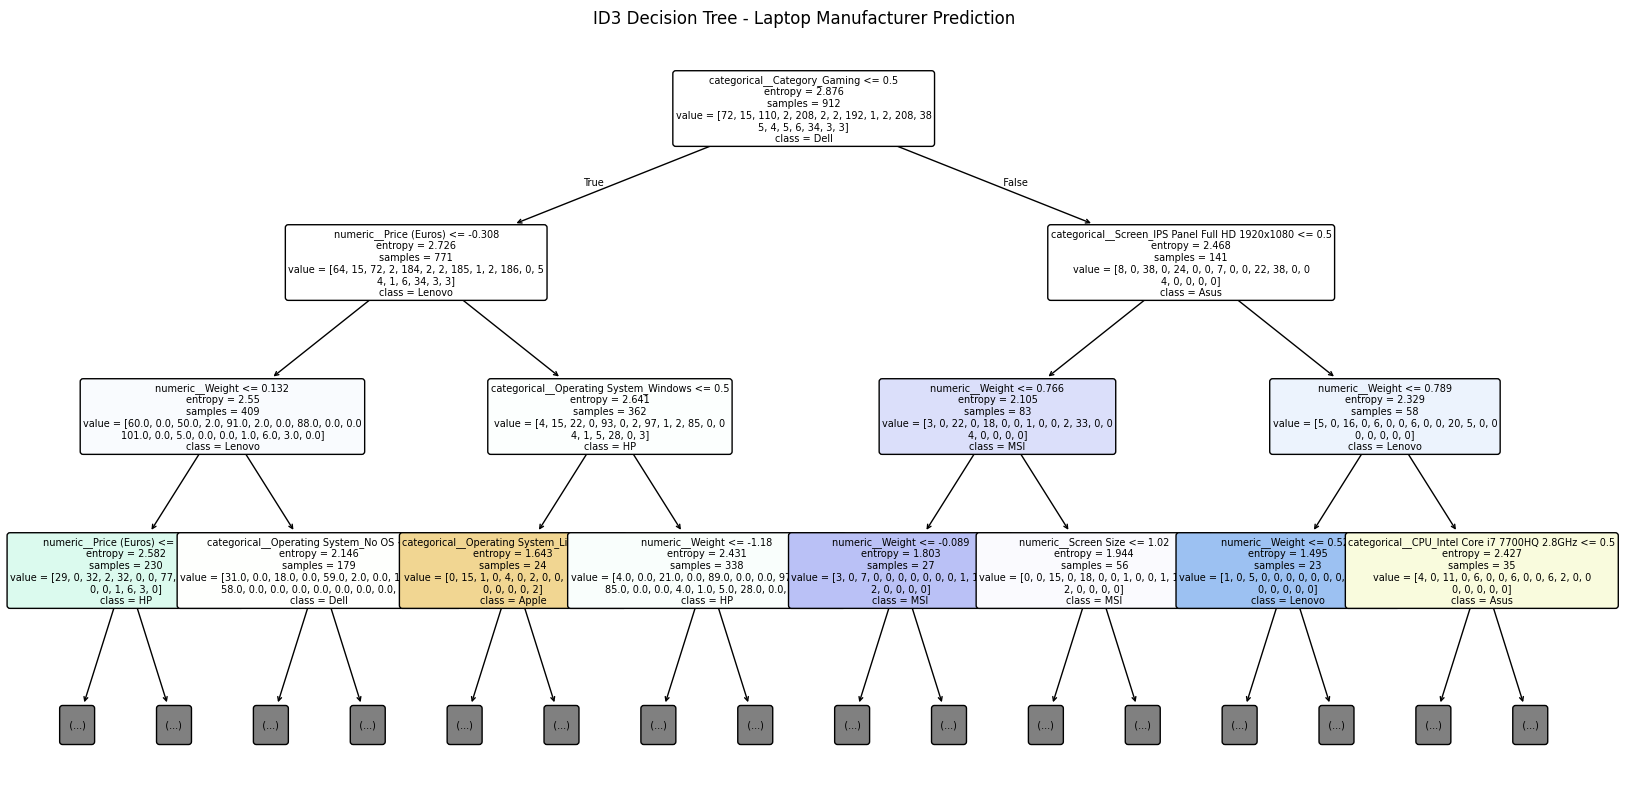

In [9]:
plt.figure(figsize=(20, 10))

plot_tree(
    id3_model.named_steps["classifier"],
    max_depth=3,
    filled=True,
    feature_names=id3_model.named_steps[
        "preprocessing"
    ].get_feature_names_out(),
    class_names=le.classes_,
    rounded=True,
    fontsize=7
)

plt.title("ID3 Decision Tree - Laptop Manufacturer Prediction")
plt.show()

In [10]:
svm_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", SVC(kernel="linear"))
])

svm_model.fit(x_train, y_train)

print("SVM Model Trained Successfully!")

SVM Model Trained Successfully!


In [11]:
y_pred_svm = svm_model.predict(x_test)

print("SVM Accuracy:",
      round(accuracy_score(y_test, y_pred_svm) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_svm,
    labels=np.arange(len(le.classes_)),
    target_names=le.classes_,
    zero_division=0
))

SVM Accuracy: 57.29 %

Classification Report:
              precision    recall  f1-score   support

        Acer       0.69      0.65      0.67        31
       Apple       1.00      1.00      1.00         6
        Asus       0.42      0.35      0.39        48
       Chuwi       1.00      1.00      1.00         1
        Dell       0.57      0.57      0.57        89
     Fujitsu       0.00      0.00      0.00         1
      Google       1.00      1.00      1.00         1
          HP       0.52      0.59      0.55        82
      Huawei       0.00      0.00      0.00         1
          LG       1.00      1.00      1.00         1
      Lenovo       0.62      0.63      0.62        89
         MSI       0.50      0.75      0.60        16
    Mediacom       1.00      1.00      1.00         2
   Microsoft       1.00      1.00      1.00         2
       Razer       1.00      0.50      0.67         2
     Samsung       0.00      0.00      0.00         3
     Toshiba       0.50      0.36  

In [12]:
knn_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", KNeighborsClassifier(n_neighbors=3))
])

knn_model.fit(x_train, y_train)

print("KNN Model Trained Successfully!")

KNN Model Trained Successfully!


In [13]:
y_pred_knn = knn_model.predict(x_test)

print("KNN Accuracy:",
      round(accuracy_score(y_test, y_pred_knn) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_knn,
    labels=np.arange(len(le.classes_)),
    target_names=le.classes_,
    zero_division=0
))

KNN Accuracy: 48.59 %

Classification Report:
              precision    recall  f1-score   support

        Acer       0.33      0.58      0.42        31
       Apple       1.00      1.00      1.00         6
        Asus       0.35      0.33      0.34        48
       Chuwi       1.00      1.00      1.00         1
        Dell       0.50      0.58      0.54        89
     Fujitsu       0.00      0.00      0.00         1
      Google       1.00      1.00      1.00         1
          HP       0.51      0.51      0.51        82
      Huawei       0.00      0.00      0.00         1
          LG       1.00      1.00      1.00         1
      Lenovo       0.61      0.42      0.49        89
         MSI       0.48      0.62      0.54        16
    Mediacom       1.00      0.50      0.67         2
   Microsoft       1.00      0.50      0.67         2
       Razer       1.00      0.50      0.67         2
     Samsung       0.00      0.00      0.00         3
     Toshiba       0.33      0.21  

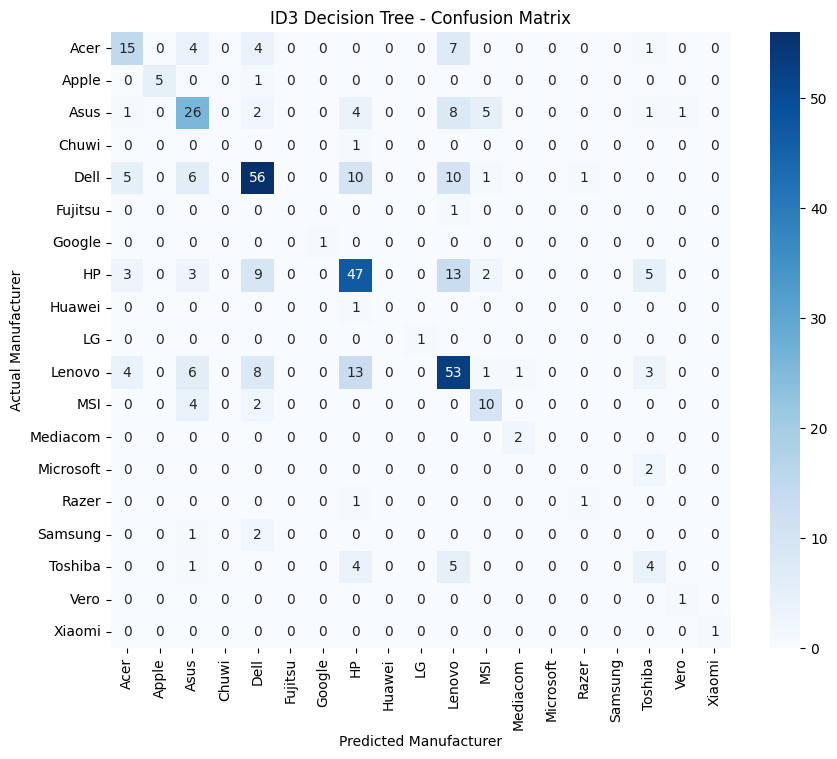

In [14]:
cm_id3 = confusion_matrix(y_test, y_pred_id3)

plt.figure(figsize=(10,8))
sns.heatmap(
    cm_id3,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=le.classes_,
    yticklabels=le.classes_
)

plt.title("ID3 Decision Tree - Confusion Matrix")
plt.xlabel("Predicted Manufacturer")
plt.ylabel("Actual Manufacturer")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.show()

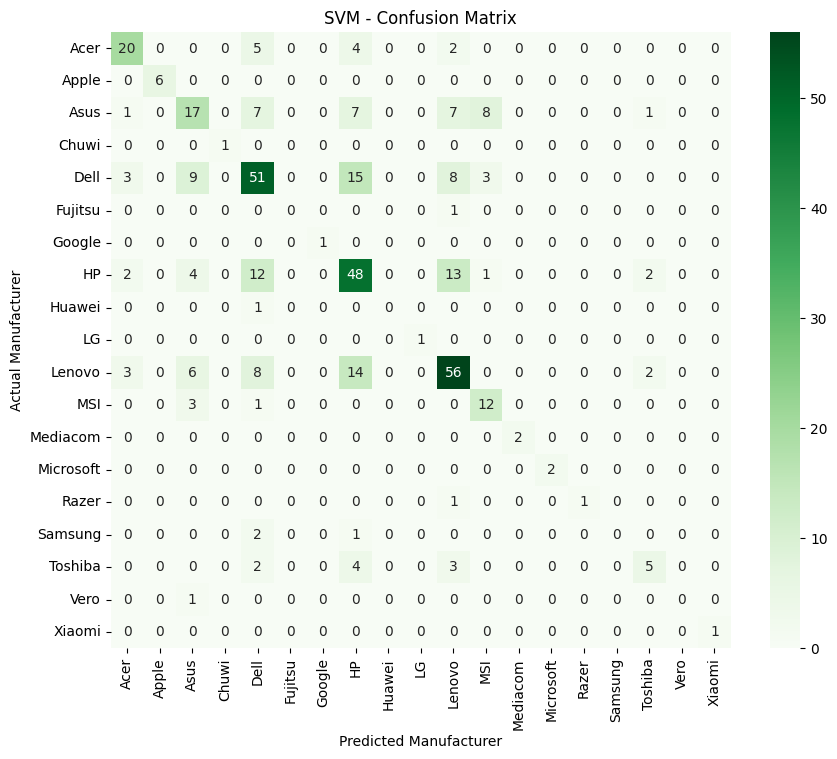

In [15]:
cm_svm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(10,8))
sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=le.classes_,
    yticklabels=le.classes_
)

plt.title("SVM - Confusion Matrix")
plt.xlabel("Predicted Manufacturer")
plt.ylabel("Actual Manufacturer")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.show()

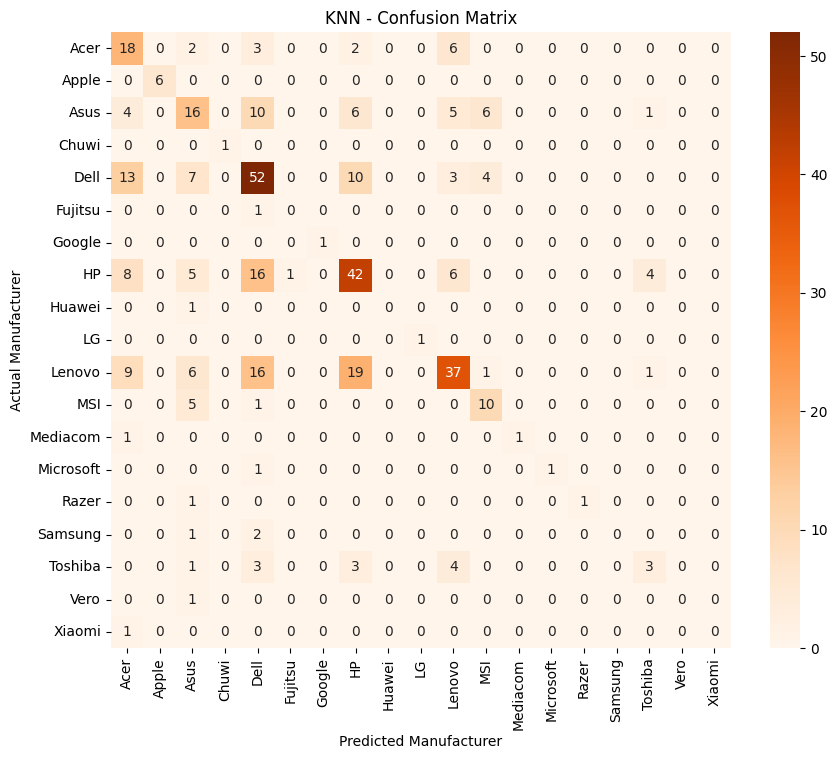

In [16]:
cm_knn = confusion_matrix(y_test, y_pred_knn)

plt.figure(figsize=(10,8))
sns.heatmap(
    cm_knn,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=le.classes_,
    yticklabels=le.classes_
)

plt.title("KNN - Confusion Matrix")
plt.xlabel("Predicted Manufacturer")
plt.ylabel("Actual Manufacturer")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.show()

In [17]:
comparison = pd.DataFrame({
    "Algorithm": [
        "ID3 Decision Tree",
        "SVM",
        "KNN"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_id3),
        accuracy_score(y_test, y_pred_svm),
        accuracy_score(y_test, y_pred_knn)
    ]
})

comparison["Accuracy Percentage"] = (
    comparison["Accuracy"] * 100
).round(2)

display(comparison)

best_model = comparison.loc[
    comparison["Accuracy"].idxmax()
]

print("Best Performing Algorithm:", best_model["Algorithm"])
print("Accuracy:", best_model["Accuracy Percentage"], "%")

,Algorithm,Accuracy,Accuracy Percentage
0,ID3 Decision Tree,0.570332,57.03
1,SVM,0.572890,57.29
2,KNN,0.485934,48.59


Best Performing Algorithm: SVM
Accuracy: 57.29 %


In [18]:
new_laptop = pd.DataFrame([{
    "Category": "Ultrabook",
    "Screen Size": 13.3,
    "Screen": "IPS Panel Retina Display 2560x1600",
    "CPU": "Intel Core i5 2.3GHz",
    "RAM": 8,
    "Storage": "128GB SSD",
    "GPU": "Intel Iris Plus Graphics 640",
    "Operating System": "macOS",
    "Operating System Version": "Unknown",
    "Weight": 1.37,
    "Price (Euros)": 1339.69
}])

for name, model in [
    ("ID3 Decision Tree", id3_model),
    ("SVM", svm_model),
    ("KNN", knn_model)
]:
    prediction = model.predict(new_laptop)
    manufacturer = le.inverse_transform(prediction)[0]
    print(name, "Prediction:", manufacturer)

ID3 Decision Tree Prediction: Apple
SVM Prediction: Apple
KNN Prediction: Apple
